Iteration: 0 Best Distance: 289.0
Iteration: 10 Best Distance: 289.0
Iteration: 20 Best Distance: 289.0
Iteration: 30 Best Distance: 289.0
Iteration: 40 Best Distance: 289.0
Iteration: 50 Best Distance: 289.0
Iteration: 60 Best Distance: 289.0
Iteration: 70 Best Distance: 289.0
Iteration: 80 Best Distance: 289.0
Iteration: 90 Best Distance: 289.0

--- OPTIMIZED URBAN ROUTE ---
C4 -> C8 -> C6 -> C7 -> C2 -> C1 -> C3 -> C5 -> C4
Shortest Distance: 289.0 units


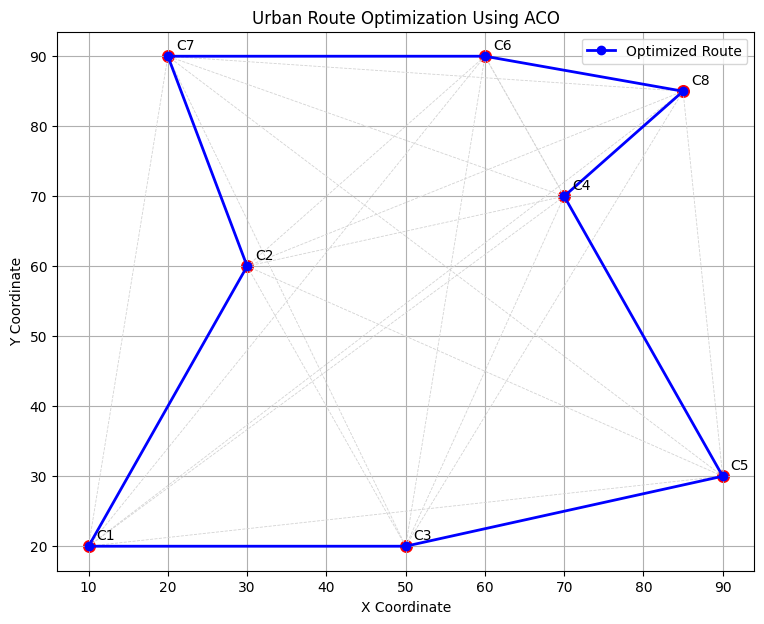

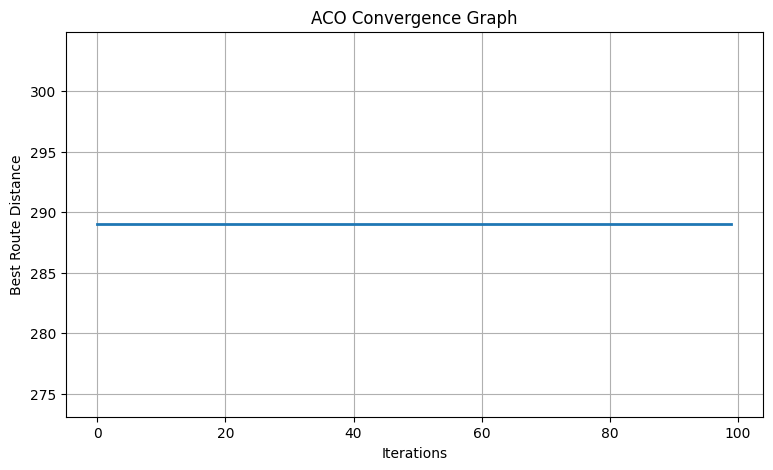

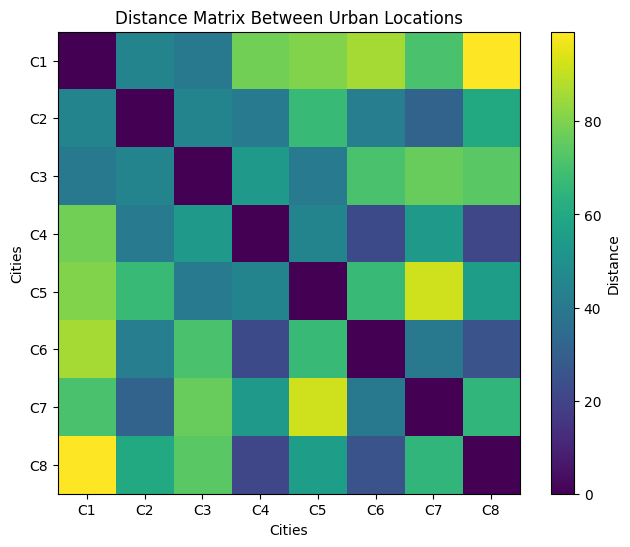

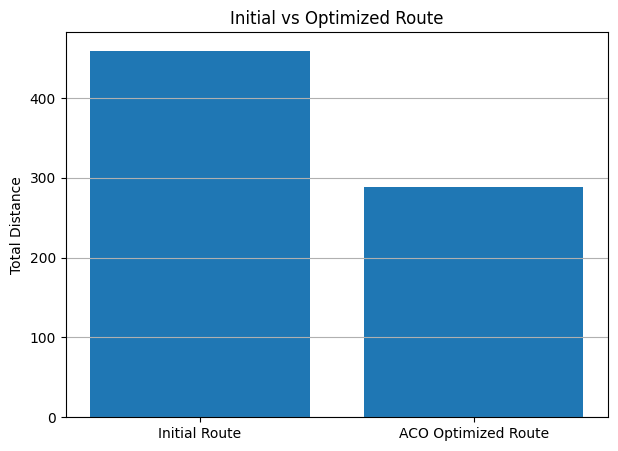

In [4]:

import numpy as np
import matplotlib.pyplot as plt
import random

# Urban locations
cities = {
    "C1": (10, 20),
    "C2": (30, 60),
    "C3": (50, 20),
    "C4": (70, 70),
    "C5": (90, 30),
    "C6": (60, 90),
    "C7": (20, 90),
    "C8": (85, 85)
}

names = list(cities.keys())
points = np.array(list(cities.values()))
N = len(points)

# ACO parameters
ANTS = 20
ITERATIONS = 100
ALPHA = 1
BETA = 2
EVAPORATION = 0.5
Q = 100

random.seed(42)
np.random.seed(42)

# Calculate distance matrix
dist = np.zeros((N, N))

for i in range(N):
    for j in range(N):
        dist[i][j] = np.linalg.norm(
            points[i] - points[j]
        )

# Initialize pheromone
pheromone = np.ones((N, N))

# Calculate route distance
def route_distance(route):
    total = 0

    for i in range(len(route)):
        a = route[i]
        b = route[(i + 1) % N]
        total += dist[a][b]

    return total

# Select next city
def select_next(current, unvisited):
    probabilities = []

    for city in unvisited:
        p = (pheromone[current][city] ** ALPHA)
        h = (1 / dist[current][city]) ** BETA
        probabilities.append(p * h)

    probabilities = np.array(probabilities)
    probabilities /= probabilities.sum()

    return random.choices(
        unvisited, weights=probabilities, k=1
    )[0]

# Construct ant route
def create_route():
    start = random.randrange(N)
    route = [start]

    unvisited = [
        i for i in range(N) if i != start
    ]

    while unvisited:
        next_city = select_next(
            route[-1], unvisited
        )

        route.append(next_city)
        unvisited.remove(next_city)

    return route

# Main ACO algorithm
best_route = None
best_distance = float("inf")
history = []

for iteration in range(ITERATIONS):

    all_routes = []

    for ant in range(ANTS):
        route = create_route()
        length = route_distance(route)

        all_routes.append((route, length))

        if length < best_distance:
            best_distance = length
            best_route = route.copy()

    # Pheromone evaporation
    pheromone *= (1 - EVAPORATION)

    # Pheromone deposit
    for route, length in all_routes:
        deposit = Q / length

        for i in range(N):
            a = route[i]
            b = route[(i + 1) % N]

            pheromone[a][b] += deposit
            pheromone[b][a] += deposit

    history.append(best_distance)

    if iteration % 10 == 0:
        print("Iteration:", iteration,
              "Best Distance:", round(best_distance, 2))

# Final route
print("\n--- OPTIMIZED URBAN ROUTE ---")

for city in best_route:
    print(names[city], end=" -> ")

print(names[best_route[0]])
print("Shortest Distance:",
      round(best_distance, 2), "units")

# Plot 1: Optimized route
route = best_route + [best_route[0]]

plt.figure(figsize=(9, 7))

for i in range(N):
    for j in range(i + 1, N):
        plt.plot(
            [points[i][0], points[j][0]],
            [points[i][1], points[j][1]],
            color="lightgray",
            linestyle="--",
            linewidth=0.6
        )

plt.plot(
    points[route, 0],
    points[route, 1],
    "b-o",
    linewidth=2,
    label="Optimized Route"
)

for i, name in enumerate(names):
    plt.text(
        points[i][0] + 1,
        points[i][1] + 1,
        name
    )

plt.scatter(
    points[:, 0], points[:, 1],
    color="red", s=70
)

plt.title("Urban Route Optimization Using ACO")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.legend()
plt.grid()
plt.show()

# Plot 2: Convergence graph
plt.figure(figsize=(9, 5))

plt.plot(history, linewidth=2)

plt.xlabel("Iterations")
plt.ylabel("Best Route Distance")
plt.title("ACO Convergence Graph")
plt.grid()
plt.show()

# Plot 3: Distance matrix heatmap
plt.figure(figsize=(8, 6))

plt.imshow(dist, cmap="viridis")
plt.colorbar(label="Distance")

plt.xticks(range(N), names)
plt.yticks(range(N), names)

plt.title("Distance Matrix Between Urban Locations")
plt.xlabel("Cities")
plt.ylabel("Cities")
plt.show()

# Plot 4: Route comparison
initial_route = list(range(N))
initial_distance = route_distance(initial_route)

plt.figure(figsize=(7, 5))

plt.bar(
    ["Initial Route", "ACO Optimized Route"],
    [initial_distance, best_distance]
)

plt.ylabel("Total Distance")
plt.title("Initial vs Optimized Route")
plt.grid(axis="y")
plt.show()
